# One backbone, many tasks: LayoutLMv3 for document AI

This notebook demonstrates an architecture for processing business documents with machine
learning. It trains on two datasets at once: **company documents** (invoices, purchase orders,
shipping orders and inventory reports from the Kaggle *Company Documents* set) and **synthetic
bank documents** (statements, cheques, pay stubs, utility bills, letters).

1. **Pretrain one powerful encoder.** LayoutLMv3 reads the page's **words, their positions, and
   the page image together** in a single Transformer. We continue its pretraining on our own
   pages with **span-masked language modelling (MLM)** and **masked image modelling (MIM)**. No
   labels are needed, so every unlabelled page you have makes the backbone better.
2. **Plug small task models into it.** With the backbone frozen, each task trains a tiny LoRA
   adapter plus a head:
   - one **document classifier** for all 9 page types, which reads *all pages of a bundle*
     through a Transformer and labels each page, including where a new document starts;
   - one **field extractor per document type** (8 of them) that tags words with fields.
3. **Serve with the backbone loaded once.** All 9 adapters live on the same in-memory backbone.
   Switching from "classify" to "extract invoice fields" means activating a different adapter
   (microseconds). It never means loading another 500 MB model.

> ⚠️ **Licence:** `microsoft/layoutlmv3-base` weights are **CC BY-NC-SA 4.0 (non-commercial)**.

**Data realism.** Both datasets are rendered from templates, so clean pages are close to trivial:
an earlier clean run scored 100% on everything. Every page here is therefore degraded like a bad
scan (skew, blur, noise, stains, low resolution, JPEG) and **re-OCR'd**, so OCR errors are part
of training and test data, as they would be in production.

**Ablations (section 12).** The same downstream training is repeated on three alternative
backbones:
- no domain pretraining (public weights only);
- pretraining without MIM;
- pretraining without MLM.

This measures what each part of the backbone recipe contributes.

The code lives in the `lmv3docs` package in this repo; this notebook drives it and visualises
each step. `RUN = "full"` trains on all data and needs a CUDA GPU. `RUN = "quick"` uses a small
subset to show the mechanics on any machine.

## Why this architecture

| Strength | How it shows up |
|---|---|
| **Multimodal understanding** | Text, 2D layout and pixels are attended to jointly. A date in a purchase order's header table, a date after "Shipped Date:" and a date in an invoice header play different roles. |
| **Learns from unlabelled data** | MLM + MIM pretraining adapts the backbone to your fonts, layouts, scan quality and vocabulary before you label anything. |
| **Small task footprint** | Each task adds only a LoRA adapter (about 2 MB) and a head. A new doc type costs megabytes, not another backbone. |
| **Low-latency serving** | One backbone in GPU memory. Switching between tasks just changes which adapter is active, with no model loading or cold start. |
| **Decoupled tasks** | Retraining the invoice extractor cannot change shipping-order predictions: their weights are separate. |
| **Whole-document context** | The classifier sees every page of a bundle, so continuation pages, mixed bundles and document boundaries are handled. |
| **Encoder-only** | One forward pass per page, with no autoregressive decoding, so latency is predictable. |

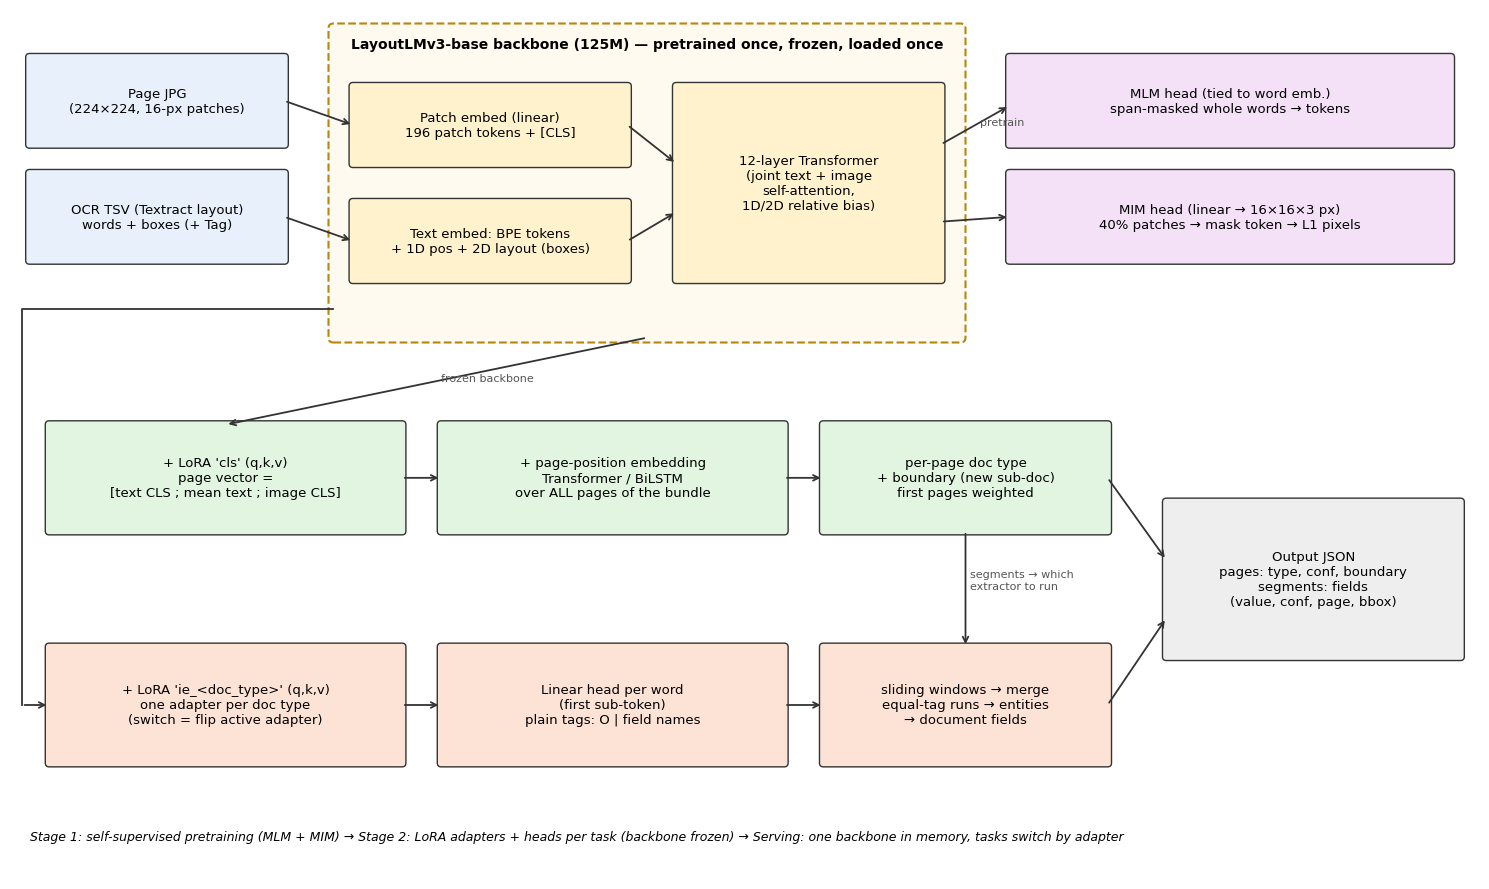

In [1]:
# ---------------------------------------------------------------- Architecture
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import warnings; warnings.filterwarnings("ignore", category=FutureWarning); warnings.filterwarnings("ignore", message=".*IProgress.*")

from lmv3docs import viz
viz.draw_architecture()

## 1. Configuration
Every setting lives in `CONFIG.yml`. `RUN` picks the training size:
- `"full"`: all bundles from both datasets, on a CUDA GPU in bf16 (about 2 h on an RTX 4070).
- `"quick"`: a small stratified subset and a few steps, so it finishes on a CPU.

In [2]:
import json, time, copy, hashlib
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from lmv3docs.config import load_config, all_field_specs
from lmv3docs.training import get_device

RUN = "full"                       # "full" (GPU) | "quick"
# Sized for a 12 GB GPU (RTX 4070): keep peak memory under ~10 GB. Above the card's memory, Windows
# silently spills into system RAM and training slows down ~20x (seen with extractor batch 8).
FULL_RUN_OVERRIDES = ["pretrain.steps=4000", "pretrain.batch_size=4",          # ~16k page passes ≈ 5 epochs
                      "classifier.epochs=5", "classifier.train_max_pages=5",   # ≤5 pages with grads per step
                      "extraction.epochs=8", "extraction.batch_size=4"]       # same settings for every ablation
RUN_ABLATIONS = True               # section 12: retrain with no-pretrain / MLM-only / MIM-only backbones
GPU_MEMORY_FRACTION = 0.87         # hard cap for PyTorch (~10.4 GB of 12): fail loudly instead of spilling
OVERRIDES = {
    "full": ["data.cache_images=true", "output_dir=artifacts/pipeline"] + FULL_RUN_OVERRIDES,
    "quick": ["data.cache_images=true", "model.max_seq_len=256", "pretrain.steps=60", "pretrain.batch_size=2",
              "classifier.epochs=2", "classifier.train_max_pages=6", "extraction.epochs=3", "extraction.batch_size=4",
              "extraction.lr=1e-3", "extraction.head_lr=3e-3", "output_dir=artifacts/pipeline_quick"],
}
QUICK_BUNDLES = {"company_docs": 60, "synthetic": 40}      # "quick" only: bundles sampled per dataset

cfg = load_config("CONFIG.yml", OVERRIDES[RUN])
specs = all_field_specs(cfg)
device = get_device()
if device.type == "cuda":
    torch.cuda.set_per_process_memory_fraction(GPU_MEMORY_FRACTION)
if RUN == "full" and device.type != "cuda":
    print("WARNING: RUN='full' without a CUDA GPU will take days; use RUN='quick' on CPU.")
torch.manual_seed(13); np.random.seed(13)
print(f"RUN={RUN} | device: {device}" + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else "")
      + f" | seq len {cfg['model']['max_seq_len']} | pretrain steps {cfg['pretrain']['steps']} x batch {cfg['pretrain']['batch_size']}"
      + f" | classifier epochs {cfg['classifier']['epochs']} | extractor epochs {cfg['extraction']['epochs']}")
pd.DataFrame({"doc type": list(specs), "fields (* = multi-valued)": [", ".join(f["name"] + ("*" if f["multi"] else "") for f in s) for s in specs.values()]}).set_index("doc type")

RUN=full | device: cuda (NVIDIA GeForce RTX 4070) | seq len 512 | pretrain steps 4000 x batch 4 | classifier epochs 5 | extractor epochs 8


,fields (* = multi-valued)
doc type,
invoice,"order_id, customer_id, order_date, contact_nam..."
purchase_order,"order_id, order_date, customer_name, product_i..."
shipping_order,"order_id, ship_name, ship_address, ship_city, ..."
inventory_report,"report_month, category*, category_id, product_..."
bank_statement,"bank_name, account_holder_name, account_number..."
cheque,"payee_name, amount_numeric, amount_words, cheq..."
pay_stub,"employer_name, employee_name, pay_date, gross_..."
utility_bill,"customer_name, account_number, bill_date, due_..."


## 2. Data — two datasets, one training set

### Company Documents (Kaggle, Apache-2.0), prepared by `python prepare_data.py`

The source is 2,676 PDFs generated from the Northwind database:

| Class | Source | Pages |
|---|---|---|
| `invoice` | `invoice_<order>.pdf` | 1 |
| `purchase_order` | `purchase_orders_<order>.pdf` | 1 |
| `shipping_order` | `order_<order>.pdf` | mostly 2, so continuation pages exist |
| `inventory_report` | `StockReport_<YYYY-MM>[_<category>].pdf` | 1 |

- **Bundles.** Files that share their number are one bundle: an order packet (invoice +
  purchase order + shipping order for one order ID) or a monthly stock packet (the summary report
  plus 8 category reports). Documents are shuffled inside each bundle, so the classifier must
  recognise every page from its content and find where each document starts.
- **OCR and labels.**
  1. Each PDF page is rendered to a JPG and read by **docTR**, which writes an OCR TSV in the AWS
     Textract layout.
  2. Field values are tagged on the PDF's exact text layer using the layout: the value after
     "Order ID:", the cell under the "Customer Name" header, and so on.
  3. Each tag is copied to the OCR word in the same place on the page, so labels don't depend on
     OCR spelling.

### Synthetic bank documents (`lmv3docs/synthetic.py`, generated if missing)

- **Bundles:** 1–3 documents each, drawn from statements, cheques, pay stubs, utility bills and
  letters (`other`).
- **Realism:** varied captions, distractor numbers and dates, OCR character confusions, blur and
  JPEG noise. Labels are exact because the renderer knows every word.

Both datasets use the same format (page JPG + Textract-layout TSV with a `Tag` column + JSONL
manifest). Their doc types don't overlap, so they simply concatenate.

### Noise: every page is a "bad scan" (`python prepare_noisy.py`, `lmv3docs/noise.py`)

Each page (train, val **and** test) gets a random degradation, with severity 0.2–1.0:
- perspective skew and rotation;
- uneven lighting and faded ink;
- coffee stains and fold lines;
- resolution loss, blur, sensor noise and specks;
- JPEG compression at quality 25–92.

The noisy page is then **OCR'd again with docTR**. The labels follow the known warp: every tagged
word box of the clean page is pushed through the same homography and transferred to the new OCR
words. Labels stay correct even when OCR misreads a value, so the model has to cope with OCR
errors, exactly as in production. `noise_coverage.json` records, per field, how often the field's
label survived and how often OCR still read its value correctly.

2353 bundles / 7064 pages loaded in 8s | tokens per page: median 112, max 611


split                          test  train   val   All
dataset      doc_type                                 
company_docs inventory_report    36    108    63   207
             invoice            136    561   134   831
             purchase_order     136    561   134   831
             shipping_order     254    997   234  1485
synthetic    bank_statement     223   1012   236  1471
             cheque              90    376    97   563
             other              106    493   123   722
             pay_stub            61    245    71   377
             utility_bill       105    385    87   577
All                            1147   4738  1179  7064

,bundles with this page sequence (document order is shuffled per bundle)
invoice + shipping_order + shipping_order(cont.) + purchase_order,136
cheque,126
purchase_order + shipping_order + shipping_order(cont.) + invoice,122
invoice + purchase_order + shipping_order + shipping_order(cont.),114
purchase_order + invoice + shipping_order + shipping_order(cont.),108
shipping_order + shipping_order(cont.) + invoice + purchase_order,104
other,95
shipping_order + shipping_order(cont.) + purchase_order + invoice,92


,field labels kept after noise,value still read correctly by OCR,hardest field for OCR
dataset,,,
company_docs_noisy,0.973,0.920,inventory_report.category_id (0.39)
synthetic_noisy,0.983,0.808,bank_statement.transaction_amount (0.65)


noise severity per page: mean 0.60, range 0.20-1.00


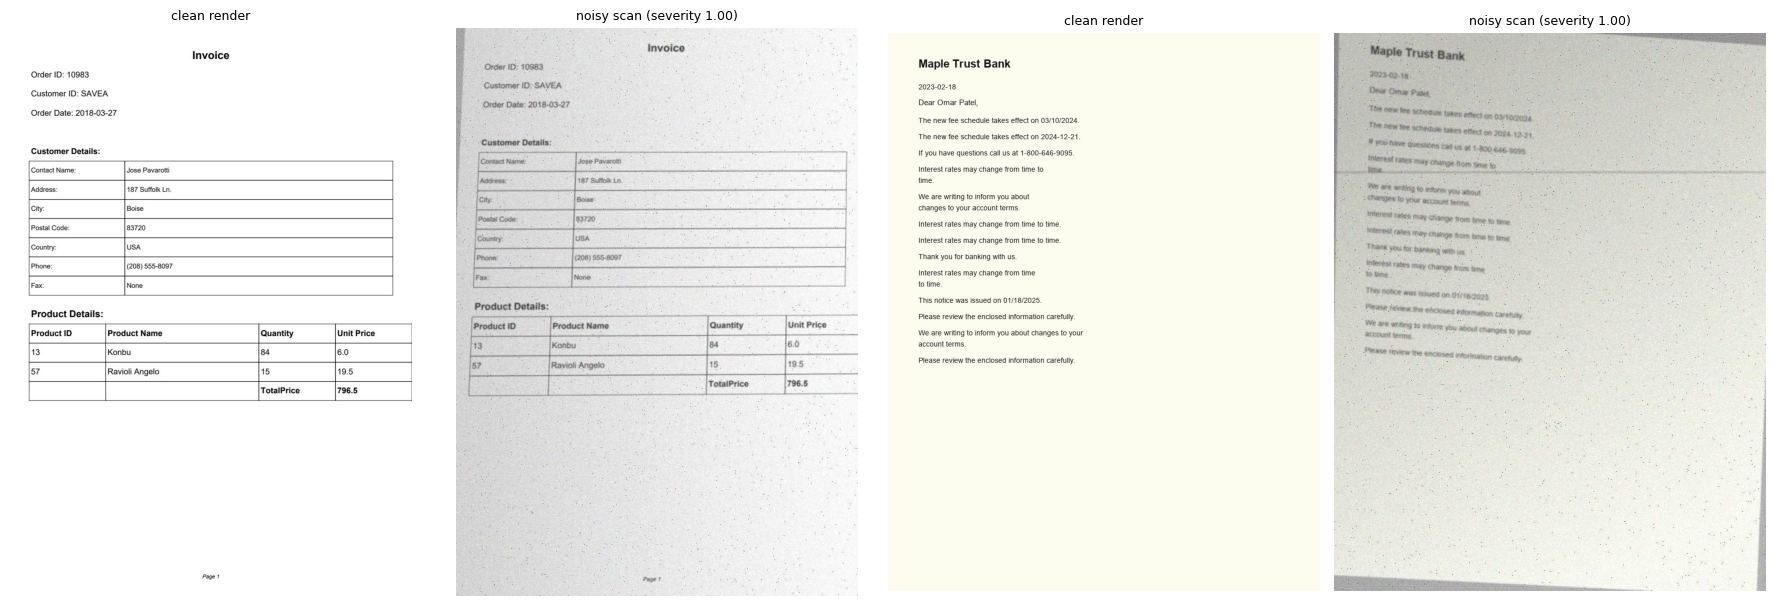

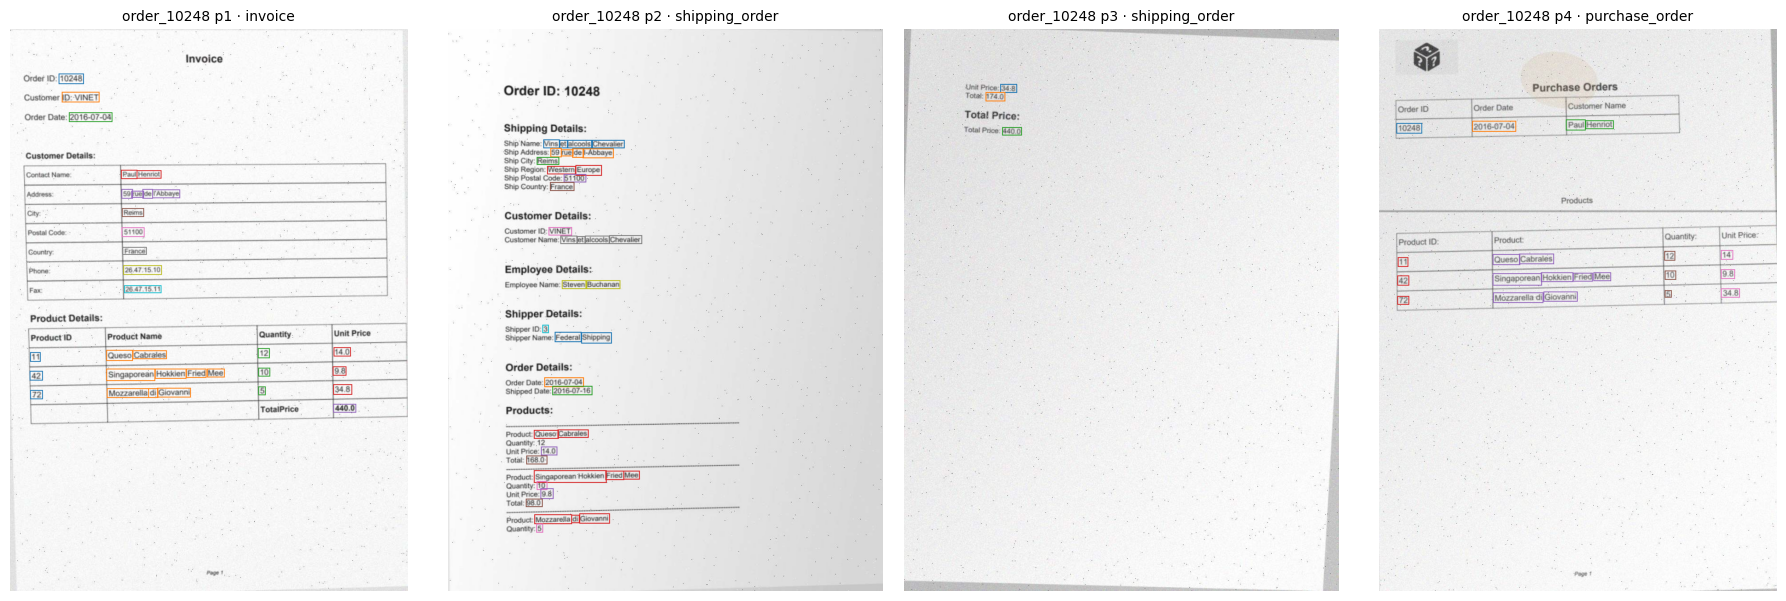

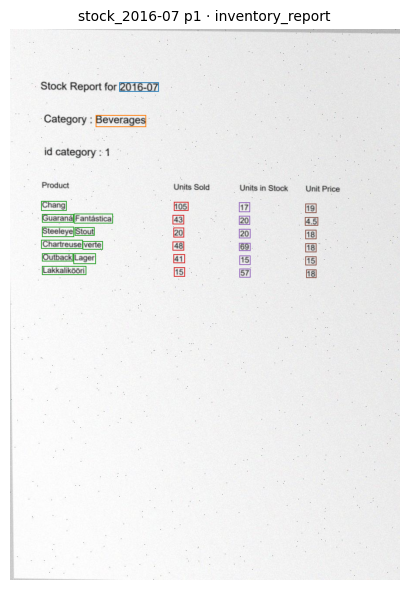

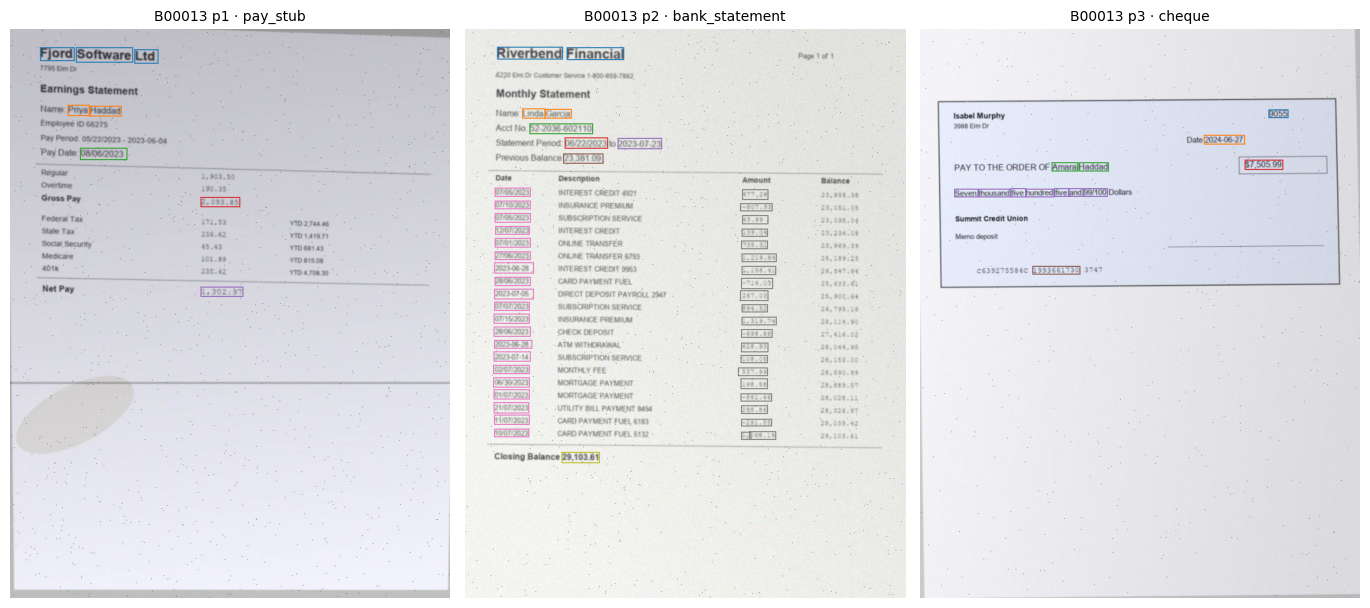

BlockType	Page	Id	Text	Confidence	Left	Top	Width	Height	Tag
LINE	1	L0	Invoice	99.6	0.44061	0.04590	0.09530	0.01855	
LINE	1	L1	Order ID: 10248	99.3	0.03040	0.08105	0.15469	0.01758	
LINE	1	L2	Customer ID:VINET	95.7	0.03178	0.11426	0.19337	0.01758	
LINE	1	L3	Order Date: 2016-07-04	93.5	0.03316	0.14941	0.22375	0.01758	
LINE	1	L4	Customer Details:	98.2	0.03730	0.21875	0.17817	0.01660	
LINE	1	L5	Contact Name:	98.2	0.03730	0.25391	0.11878	0.01465	
LINE	1	L6	Paul Henriot	97.3	0.27901	0.25195	0.10083	0.01562	
LINE	1	L7	Address:	97.5	0.03868	0.28906	0.07182	0.01367	
LINE	1	L8	59 rue de l'Abbaye	63.3	0.2


In [3]:
from lmv3docs import DocPipeline, build_bundles
from lmv3docs.data import split_bundles
from lmv3docs.datasets import ensure_datasets, load_rows, manifest_paths

ensure_datasets(cfg)                              # generates the synthetic set if missing
rows = load_rows(cfg, keep_types=set(cfg["classifier"]["doc_types"]))
if RUN == "quick":                                # stratified subset of bundles per dataset
    rng = np.random.default_rng(13)
    keep = set()
    for ds, n in QUICK_BUNDLES.items():
        ids = sorted({r["doc_id"] for r in rows if r["dataset"] == ds})
        stock = [i for i in ids if i.startswith("stock_")]
        rest = [i for i in ids if not i.startswith("stock_")]
        n_stock = min(len(stock), 6)
        keep |= set(rng.choice(rest, min(len(rest), n - n_stock), replace=False)) | set(rng.choice(stock, n_stock, replace=False) if n_stock else [])
    rows = [r for r in rows if r["doc_id"] in keep]

pipe = DocPipeline.create(cfg, device)            # tokenizer + LayoutLMv3-base backbone
t0 = time.time()
pages_all = [pipe.fz.page_from_row(r, r["_dir"]) for r in rows]
for p, r in zip(pages_all, rows):
    p.meta["dataset"] = r["dataset"]
bundles_all = build_bundles(pages_all)
splits = split_bundles(bundles_all)
pages = {k: [p for b in v for p in b] for k, v in splits.items()}
df = pd.DataFrame([{"dataset": p.meta["dataset"], "doc_type": p.doc_type, "split": p.meta["split"]} for p in pages_all])
print(f"{len(bundles_all)} bundles / {len(pages_all)} pages loaded in {time.time() - t0:.0f}s | tokens per page: median "
      f"{int(np.median([len(p.ids) for p in pages_all]))}, max {max(len(p.ids) for p in pages_all)}")
display(pd.crosstab([df.dataset, df.doc_type], df.split, margins=True))
layout = pd.Series([" + ".join(p.doc_type + ("" if p.meta["segment_start"] else "(cont.)") for p in b)
                    for b in bundles_all.values()]).value_counts().head(8)
display(layout.to_frame("bundles with this page sequence (document order is shuffled per bundle)"))

noise_rows = []
for mp in manifest_paths(cfg):
    cp = os.path.join(os.path.dirname(mp), "noise_coverage.json")
    if os.path.exists(cp):
        c = pd.DataFrame(json.load(open(cp))).T
        tot = c["total"].sum()
        noise_rows.append({"dataset": os.path.basename(os.path.dirname(mp)),
                           "field labels kept after noise": (c["tagged_rate"] * c["total"]).sum() / tot,
                           "value still read correctly by OCR": c["found"].sum() / tot,
                           "hardest field for OCR": f"{c['rate'].astype(float).idxmin()} ({c['rate'].astype(float).min():.2f})"})
if noise_rows:
    display(pd.DataFrame(noise_rows).set_index("dataset").round(3))
sev = pd.Series([r.get("noise_severity", np.nan) for r in rows])
if sev.notna().any():
    print(f"noise severity per page: mean {sev.mean():.2f}, range {sev.min():.2f}-{sev.max():.2f}")

def clean_vs_noisy(p, ax_pair):                   # clean source page next to its noisy, re-OCR'd version
    from PIL import Image
    clean_dir = p.meta["_dir"].replace("_noisy", "")
    stem = os.path.basename(p.meta["image"])
    ax_pair[0].imshow(Image.open(os.path.join(clean_dir, "pages", stem))); ax_pair[0].set_title("clean render", fontsize=9)
    ax_pair[1].imshow(Image.open(os.path.join(p.meta["_dir"], p.meta["image"]))); ax_pair[1].set_title(f"noisy scan (severity {p.meta.get('noise_severity', 0):.2f})", fontsize=9)
    for a in ax_pair: a.axis("off")
examples = [max((p for p in pages_all if p.meta["dataset"] == ds), key=lambda p: p.meta.get("noise_severity", 0)) for ds in ("company_docs", "synthetic")]
fig, axes = plt.subplots(1, 4, figsize=(18, 6))
for i, p in enumerate(examples):
    clean_vs_noisy(p, axes[2 * i:2 * i + 2])
plt.tight_layout(); plt.show()

order_bundle = next(b for b in bundles_all.values() if b[0].meta["dataset"] == "company_docs" and len(b) == 4)
viz.show_tagged_pages(order_bundle)                        # a company order packet, field words boxed by tag
viz.show_tagged_pages([next(p for p in pages_all if p.doc_type == "inventory_report")], max_pages=1)
synth_bundle = max((b for b in bundles_all.values() if b[0].meta["dataset"] == "synthetic"), key=lambda b: len({p.doc_type for p in b}))
viz.show_tagged_pages(synth_bundle)                        # a synthetic bank bundle
print(open(os.path.join(order_bundle[0].meta["_dir"], order_bundle[0].meta["ocr"]), encoding="utf-8").read()[:600])

## 3. Stage 1 — Pretrain the backbone on our pages (MLM + MIM)
- **MLM:** about 15% of words are hidden in whole-word spans, and the model must reconstruct
  them from the surrounding words, the layout and the image.
- **MIM:** about 40% of the 16×16 image patches are replaced by a learned `[MASK]` embedding,
  and the model must redraw their pixels.

Both losses train every backbone weight, and no labels are used. This is where the
backbone becomes "fluent" in your documents.

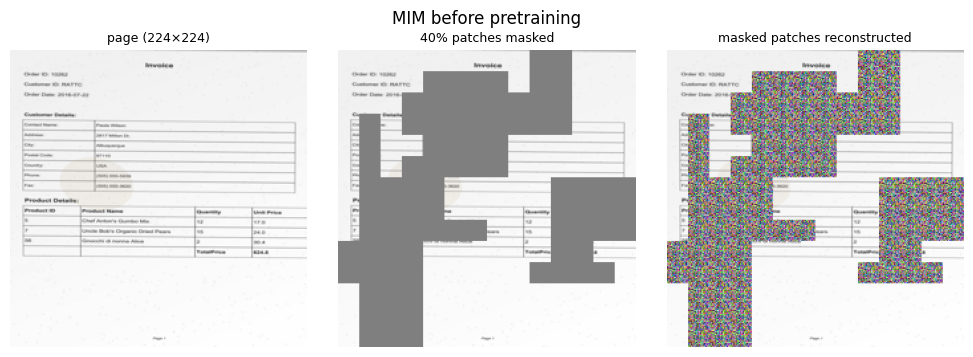

pretrain step 666/4000  mlm 3.009  mlm_acc 0.471  mim 0.069  (94s)


pretrain step 1332/4000  mlm 1.128  mlm_acc 0.739  mim 0.058  (183s)


pretrain step 1998/4000  mlm 1.647  mlm_acc 0.721  mim 0.066  (274s)


pretrain step 2664/4000  mlm 0.762  mlm_acc 0.852  mim 0.043  (363s)


pretrain step 3330/4000  mlm 1.930  mlm_acc 0.613  mim 0.047  (451s)


pretrain step 3996/4000  mlm 1.171  mlm_acc 0.759  mim 0.058  (539s)


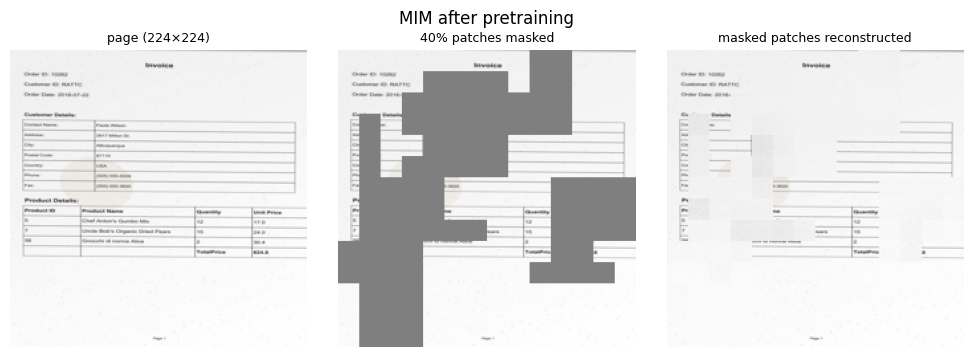

,before,after
mlm,14.610,1.275
mlm_acc,0.000,0.752
mim,0.851,0.045


In [4]:
from lmv3docs.pretraining import Pretrainer

pt = Pretrainer(pipe.backbone, pipe.fz, cfg["pretrain"], device)
mim_page = pages["val"][0]
def mim_demo(title):
    """Mask 40% of a page's patches and show what the backbone reconstructs."""
    rng = np.random.default_rng(1)
    b = pt.batch([mim_page], rng)
    pipe.backbone.eval()
    with torch.no_grad():
        _, _, patch_h = pipe.backbone(**b)
        pred = pt.heads.mim(patch_h).float()
    G, P = pt.grid, pipe.backbone.patch
    unpatch = lambda x: x.reshape(1, G, G, 3, P, P).permute(0, 3, 1, 4, 2, 5).reshape(1, 3, G * P, G * P)
    orig = b["pixel_values"].float().cpu()
    m = b["patch_mask"][0].cpu().reshape(G, G).repeat_interleave(P, 0).repeat_interleave(P, 1)
    masked = orig.clone(); masked[:, :, m] = 0
    recon = orig.clone(); recon[:, :, m] = unpatch(pred.cpu())[:, :, m]
    show = lambda t: ((t[0].permute(1, 2, 0).numpy() * 0.5 + 0.5).clip(0, 1))
    fig, ax = plt.subplots(1, 3, figsize=(10, 3.6))
    for a, img, t in zip(ax, [orig, masked, recon], ["page (224×224)", "40% patches masked", "masked patches reconstructed"]):
        a.imshow(show(img)); a.set_title(t, fontsize=9); a.axis("off")
    plt.suptitle(title); plt.tight_layout(); plt.show()
    pipe.backbone.train()

before = pt.evaluate(pages["val"])
mim_demo("MIM before pretraining")
pt.train(pages["train"])
after = pt.evaluate(pages["val"])
mim_demo("MIM after pretraining")
display(pd.DataFrame({"before": before, "after": after}).round(3))

## 4. Freeze the backbone. From here on it never changes.
Every downstream model below trains only **its own** LoRA adapter and head.

In [5]:
pipe.backbone.freeze()
pt.heads.cpu()                                   # pretraining heads are no longer needed on the GPU
if device.type == "cuda":
    torch.cuda.empty_cache()                     # release the full-backbone training memory
trainable = sum(p.numel() for p in pipe.backbone.parameters() if p.requires_grad)
print(f"backbone parameters: {sum(p.numel() for p in pipe.backbone.parameters()) / 1e6:.1f}M, trainable now: {trainable}")
backbone_fingerprint = hashlib.sha256(b"".join(v.numpy().tobytes() for v in pipe.backbone.base_state_dict().values())).hexdigest()[:16]
print("backbone fingerprint:", backbone_fingerprint)

backbone parameters: 125.3M, trainable now: 0


backbone fingerprint: f1a26997a27bf608


## 5. Stage 2a — Document classifier: LoRA `cls` + Transformer over all pages
- **Page vector:** `[text CLS ; mean text ; image CLS]` plus a page-position embedding.
- **Document encoder:** a Transformer attends across the bundle and outputs **a doc type per
  page** plus a **boundary** flag.
- **Loss weighting:** first pages of each document get extra weight (2.0, decaying per page),
  and rarer classes are up-weighted.

In [6]:
from lmv3docs.classifier import train_classifier
clf = pipe.add_classifier(cfg["classifier"]["doc_types"], cfg["classifier"])
clf_hist = train_classifier(pipe.backbone, clf, splits["train"], splits["val"], cfg["classifier"], device)

classifier epoch 1/5  loss 0.458  val page-acc 0.999  (140s)


classifier epoch 2/5  loss 0.276  val page-acc 0.999  (269s)


classifier epoch 3/5  loss 0.275  val page-acc 0.999  (398s)


classifier epoch 4/5  loss 0.275  val page-acc 0.999  (528s)


classifier epoch 5/5  loss 0.274  val page-acc 0.999  (658s)


## 6. Stage 2b — Field extractors: one LoRA adapter + linear head per doc type
Each extractor trains only on its own doc type's pages and only touches its own adapter
`ie_<type>`. Labels are plain word tags (`O` or a field name) straight from the OCR TSV.

In [7]:
from lmv3docs.extractor import train_extractor
ie_hist = {}
for dt in specs:
    train_pages = [p for p in pages["train"] if p.doc_type == dt]
    if not train_pages:                       # e.g. a doc type missing from a small "quick" subset
        print(f"[{dt}] no training pages in this run - skipped")
        continue
    ext = pipe.add_extractor(dt, specs[dt])
    ie_hist[dt] = train_extractor(pipe.backbone, ext, train_pages, cfg["extraction"], device)
    if device.type == "cuda":
        torch.cuda.empty_cache()
print("adapters on the shared backbone:", pipe.backbone.adapters)

[invoice] 561 windows x 8 epochs  final loss 0.001  (53s)


[purchase_order] 561 windows x 8 epochs  final loss 0.000  (48s)


[shipping_order] 997 windows x 8 epochs  final loss 0.003  (110s)


[inventory_report] 108 windows x 8 epochs  final loss 0.006  (18s)


[bank_statement] 1168 windows x 8 epochs  final loss 0.001  (402s)


[cheque] 376 windows x 8 epochs  final loss 0.003  (32s)


[pay_stub] 245 windows x 8 epochs  final loss 0.002  (25s)


[utility_bill] 385 windows x 8 epochs  final loss 0.002  (35s)
adapters on the shared backbone: ['cls', 'ie_bank_statement', 'ie_cheque', 'ie_inventory_report', 'ie_invoice', 'ie_pay_stub', 'ie_purchase_order', 'ie_shipping_order', 'ie_utility_bill']


## 7. Evaluation — classification (test split)

,classification (test)
page_accuracy,1.0
macro_f1,1.0
weighted_f1,1.0
first_page_of_segment_accuracy,1.0
boundary_f1,1.0
document_exact_match,1.0
bundles,390.0
pages,1147.0


,precision,recall,f1,support
doc_type,,,,
invoice,1.0,1.0,1.0,136
purchase_order,1.0,1.0,1.0,136
shipping_order,1.0,1.0,1.0,254
inventory_report,1.0,1.0,1.0,36
bank_statement,1.0,1.0,1.0,223
cheque,1.0,1.0,1.0,90
pay_stub,1.0,1.0,1.0,61
utility_bill,1.0,1.0,1.0,105
other,1.0,1.0,1.0,106


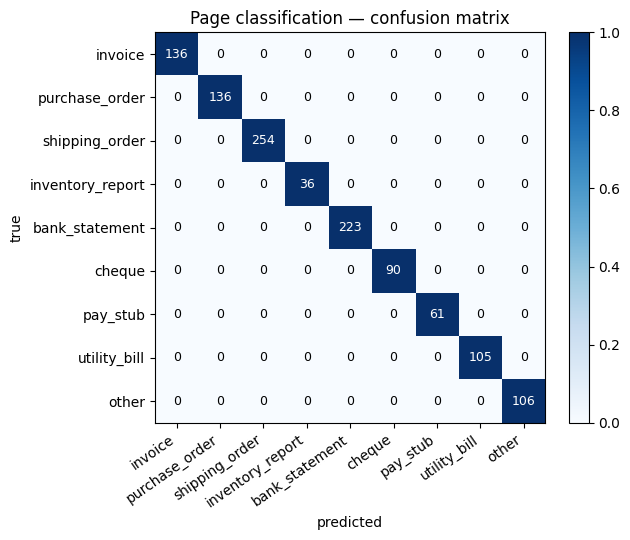

In [8]:
from lmv3docs.metrics import evaluate_classification, evaluate_extraction, latency_table
cls_sum, cls_rep, cm, cls_ms = evaluate_classification(pipe, splits["test"], cfg["classifier"])
display(pd.Series(cls_sum).round(3).to_frame("classification (test)"))
display(cls_rep.round(3))
viz.plot_confusion(cm, clf.labels)

## 8. Evaluation — field extraction (test split)
- **Strict F1:** exact word span. **Text F1:** same normalised value.
- **Document value accuracy:** the single value the API returns per field, per document.

,entity_f1_strict,entity_f1_text,doc_value_accuracy,pages
invoice,0.997,0.997,0.991,136.0
purchase_order,0.999,0.999,1.000,136.0
shipping_order,0.996,0.996,0.993,254.0
inventory_report,0.998,0.998,0.958,36.0
bank_statement,0.999,0.999,0.991,223.0
cheque,0.988,0.988,0.989,90.0
pay_stub,0.992,0.992,0.990,61.0
utility_bill,0.993,0.993,0.989,105.0


precision  recall  f1_strict  f1_text  \
doc_type       field                                                        
bank_statement account_holder_name      0.985   0.985      0.985    0.985   
               account_number           0.995   1.000      0.998    0.998   
               bank_name                1.000   1.000      1.000    1.000   
               closing_balance          1.000   1.000      1.000    1.000   
               opening_balance          1.000   1.000      1.000    1.000   
...                                       ...     ...        ...      ...   
utility_bill   account_number           1.000   1.000      1.000    1.000   
               amount_due               1.000   0.986      0.993    0.993   
               bill_date                1.000   1.000      1.000    1.000   
               customer_name            0.986   0.986      0.986    0.986   
               due_date                 0.986   0.986      0.986    0.986   

                                    support  doc_value_acc  
doc_type       field                                        
bank_statement account_holder_name      130          0.985  
               account_number           213          1.000  
               bank_name                225          1.000  
               closing_balance          126          1.000  
               opening_balance          127          1.000  
...                                     ...            ...  
utility_bill   account_number            70          1.000  
               amount_due                72          0.986  
               bill_date                 67          1.000  
               customer_name             74          0.986  
               due_date                  70          0.973  

[73 rows x 6 columns]

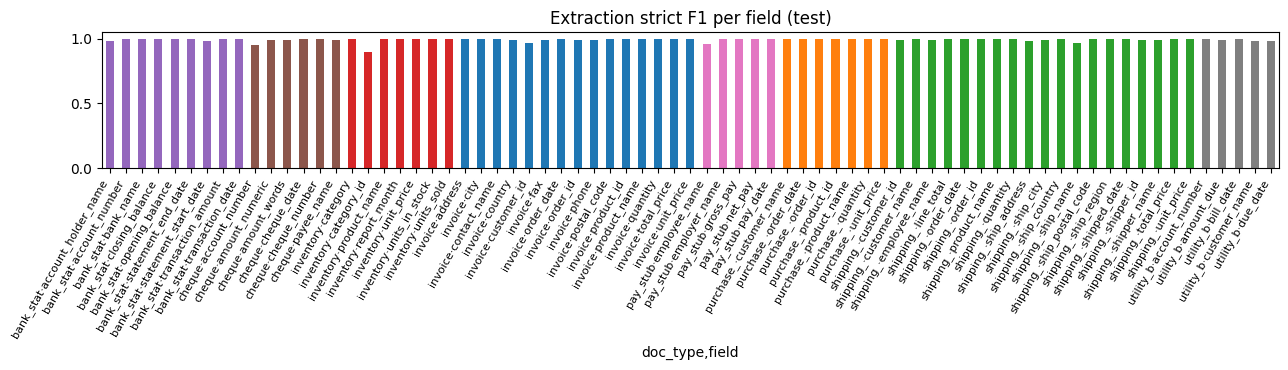

In [9]:
ie_sum, ie_rep, ie_ms = evaluate_extraction(pipe, splits["test"])
display(ie_sum.round(3))
display(ie_rep.round(3))
ax = ie_rep["f1_strict"].plot.bar(figsize=(13, 3.8), color=[plt.cm.tab10(list(specs).index(d)) for d, _ in ie_rep.index])
ax.set_xticklabels([f"{d[:9]}·{f}" for d, f in ie_rep.index], rotation=60, ha="right", fontsize=8)
ax.set_ylim(0, 1.05); ax.set_title("Extraction strict F1 per field (test)"); plt.tight_layout(); plt.show()

### Is it memorising? Split audit and never-seen values
- **Split integrity.** Splits are made per bundle (order ID, report month or synthetic bundle),
  so no page of a test bundle is ever seen in training.
- **Never-seen values.** Values such as Northwind customer names repeat across orders. The second
  table scores the extractors separately on test values that **never** occur in training. Similar
  recall on both rows means the model reads the page rather than recalling values.

In [10]:
from lmv3docs.experiments import seen_vs_unseen, split_integrity
display(pd.Series(split_integrity(pages_all), name="split audit").to_frame())
display(pd.DataFrame(seen_vs_unseen(pipe, pages)).T.round(4))

,split audit
bundles,2353
bundles_in_more_than_one_split,0


correct   total  recall
company_docs never in train   1763.0  1780.0  0.9904
             seen in train    7706.0  7715.0  0.9988
synthetic    never in train   5659.0  5674.0  0.9974
             seen in train    3408.0  3409.0  0.9997

## 9. Why serve it this way — memory, switching cost, latency
**Footprint.** The alternative is a fully fine-tuned copy of LayoutLMv3 per task. Here, every
task shares one backbone.

,params_M,fp16_MB
"backbone (shared, loaded once)",125.33,239.04
classifier: LoRA 'cls' + doc head,3.07,5.85
extractor 'invoice': LoRA + head,0.90,1.71
extractor 'purchase_order': LoRA + head,0.89,1.70
extractor 'shipping_order': LoRA + head,0.90,1.72
extractor 'inventory_report': LoRA + head,0.89,1.70
extractor 'bank_statement': LoRA + head,0.89,1.70
extractor 'cheque': LoRA + head,0.89,1.70
extractor 'pay_stub': LoRA + head,0.89,1.70
extractor 'utility_bill': LoRA + head,0.89,1.70


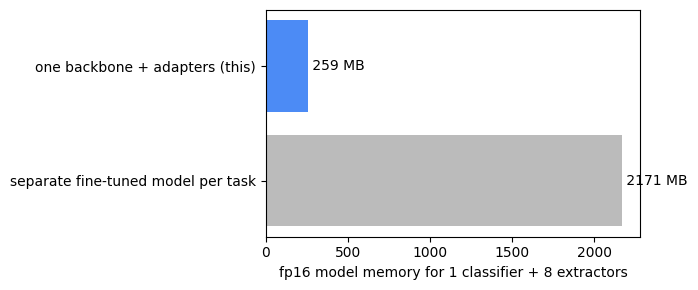

In [11]:
fp = pd.DataFrame(pipe.footprint()).T
display(fp.round(2))
n_tasks = 1 + len(pipe.extractors)
shared_mb = fp["fp16_MB"].sum()
separate_mb = n_tasks * fp.iloc[0]["fp16_MB"] + fp.iloc[1:]["fp16_MB"].sum()
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(["separate fine-tuned model per task", "one backbone + adapters (this)"], [separate_mb, shared_mb], color=["#bbb", "#4c8bf5"])
for i, v in enumerate([separate_mb, shared_mb]): ax.text(v, i, f" {v:.0f} MB", va="center")
ax.set_xlabel("fp16 model memory for 1 classifier + %d extractors" % len(pipe.extractors)); plt.tight_layout(); plt.show()

**Switching cost.** In serving, a "model swap" here means activating a different adapter. The
cell below compares that with what a swap costs when every task is its own full model:
loading another backbone from disk.

In [12]:
import tempfile
switch_us = pipe.switch_cost_us()
tmp = tempfile.mkdtemp()
pipe.backbone.save(tmp, pipe.fz.tok)
from lmv3docs.backbone import Backbone
t0 = time.perf_counter(); _bb, _ = Backbone.load(tmp, device); load_s = time.perf_counter() - t0; del _bb
display(pd.DataFrame({"time": [f"{switch_us:.0f} µs", f"{load_s:.2f} s"], "speed-up": ["", f"{load_s / (switch_us / 1e6):,.0f}x"]},
                     index=["switch adapter (this architecture)", "load another LayoutLMv3 from disk"]))
display(latency_table(**{"classify (per page, whole bundle)": cls_ms,
                         "extract (per page)": [x for v in ie_ms.values() for x in v]}).round(1))
print(f"Latency measured on {device}" + (f" ({torch.cuda.get_device_name(0)}, bf16 autocast)." if device.type == "cuda"
      else ". A GPU endpoint is far faster than this CPU run."))

,time,speed-up
switch adapter (this architecture),628 µs,
load another LayoutLMv3 from disk,0.96 s,"1,528x"


,mean_ms,p50_ms,p95_ms,pages_per_s
"classify (per page, whole bundle)",20.0,17.2,29.2,50.0
extract (per page),20.6,19.1,27.5,48.5


Latency measured on cuda (NVIDIA GeForce RTX 4070, bf16 autocast).


**Decoupling.** Retrain one extractor (invoice) and confirm nothing else changed: the backbone
fingerprint and every other adapter's weights are bit-identical, and so are their predictions.

In [13]:
from lmv3docs.lora import adapter_state_dict, remove_adapter
enc = pipe.backbone.model.encoder
digest = lambda name: hashlib.sha256(b"".join(v.numpy().tobytes() for v in adapter_state_dict(enc, name).values())).hexdigest()[:12]
retrain_dt = "invoice" if "invoice" in pipe.extractors else next(iter(pipe.extractors))     # the one we retrain
probe_dt = next(d for d in ["shipping_order", "bank_statement", *pipe.extractors] if d in pipe.extractors and d != retrain_dt)
probe = next(p for s in ("test", "val", "train") for p in pages[s] if p.doc_type == probe_dt)   # a page of another type
before_w = {n: digest(n) for n in pipe.backbone.adapters}
before_pred = pipe.extract(probe, probe_dt)

remove_adapter(enc, pipe.extractors.pop(retrain_dt).adapter)
train_extractor(pipe.backbone, pipe.add_extractor(retrain_dt, specs[retrain_dt]), [p for p in pages["train"] if p.doc_type == retrain_dt],
                cfg["extraction"], device, log=None)
after_w = {n: digest(n) for n in pipe.backbone.adapters}
fp_after = hashlib.sha256(b"".join(v.numpy().tobytes() for v in pipe.backbone.base_state_dict().values())).hexdigest()[:16]
display(pd.DataFrame({"before": before_w, f"after retraining {retrain_dt}": after_w}).assign(unchanged=lambda d: d.iloc[:, 0] == d.iloc[:, 1]))
print("backbone unchanged:", fp_after == backbone_fingerprint,
      f"| {probe_dt} predictions unchanged:", pipe.extract(probe, probe_dt) == before_pred)

,before,after retraining invoice,unchanged
cls,46ebe7b7f900,46ebe7b7f900,True
ie_bank_statement,1b486f310c68,1b486f310c68,True
ie_cheque,c93c033c6a60,c93c033c6a60,True
ie_inventory_report,1f40b2076865,1f40b2076865,True
ie_invoice,e03bde1efc81,938d0d5ee25d,False
ie_pay_stub,6222567bd9aa,6222567bd9aa,True
ie_purchase_order,13ba1eddc06c,13ba1eddc06c,True
ie_shipping_order,dcb8e8b431ce,dcb8e8b431ce,True
ie_utility_bill,e7f6f693b378,e7f6f693b378,True


backbone unchanged: True | shipping_order predictions unchanged: True


## 10. Serving: save the final weights in fp16, reload them (backbone once + adapters), process raw inputs
The trained model is saved as one serving bundle, with **every weight stored in fp16** (half
precision, half the size of fp32):
- `backbone/model.safetensors`: the LayoutLMv3 backbone, without adapters
- `adapters/<name>.safetensors`: the LoRA adapter for each task
- `heads/*.safetensors`: the classifier head and one tag head per extractor

Loading upcasts to fp32 for computation. This is what an endpoint does: load the pipeline once
at start-up, then turn each request (page images + OCR TSV text) into page types, document
boundaries and fields.

,tensors,dtype,MB
file,,,
adapters/cls.safetensors,72,F16,1.69
adapters/ie_bank_statement.safetensors,72,F16,1.69
adapters/ie_cheque.safetensors,72,F16,1.69
adapters/ie_inventory_report.safetensors,72,F16,1.69
adapters/ie_invoice.safetensors,72,F16,1.69
adapters/ie_pay_stub.safetensors,72,F16,1.69
adapters/ie_purchase_order.safetensors,72,F16,1.69
adapters/ie_shipping_order.safetensors,72,F16,1.69
adapters/ie_utility_bill.safetensors,72,F16,1.69


saved 263 MB -> reloaded in 1.3s; adapters: ['cls', 'ie_bank_statement', 'ie_cheque', 'ie_inventory_report', 'ie_invoice', 'ie_pay_stub', 'ie_purchase_order', 'ie_shipping_order', 'ie_utility_bill']


true page types: ['shipping_order', 'shipping_order', 'invoice', 'purchase_order'] | reloaded fp16 bundle gives the same segments as the in-memory model: True
{
 "document_id": "order_10263",
 "pages": [
  {
   "page_num": 1,
   "doc_type": "shipping_order",
   "confidence": 0.96,
   "segment_start": true
  },
  {
   "page_num": 2,
   "doc_type": "shipping_order",
   "confidence": 0.96,
   "segment_start": false
  },
  {
   "page_num": 3,
   "doc_type": "invoice",
   "confidence": 0.9599,
   "segment_start": true
  },
  "... 1 more"
 ],
 "segments": [
  {
   "doc_type": "shipping_order",
   "pages": [
    1,
    2
   ],
   "confidence": 0.96,
   "fields": {
    "order_id": {
     "value": "10263",
     "confidence": 0.9999194145202637,
     "page": 1
    },
    "ship_name": {
     "value": "Emst Handel",
     "confidence": 0.999900221824646,
     "page": 1
    },
    "ship_address": {
     "value": "Kirchgasse 6",
     "confidence": 0.9999744892120361,
     "page": 1
    },
    "ship_c

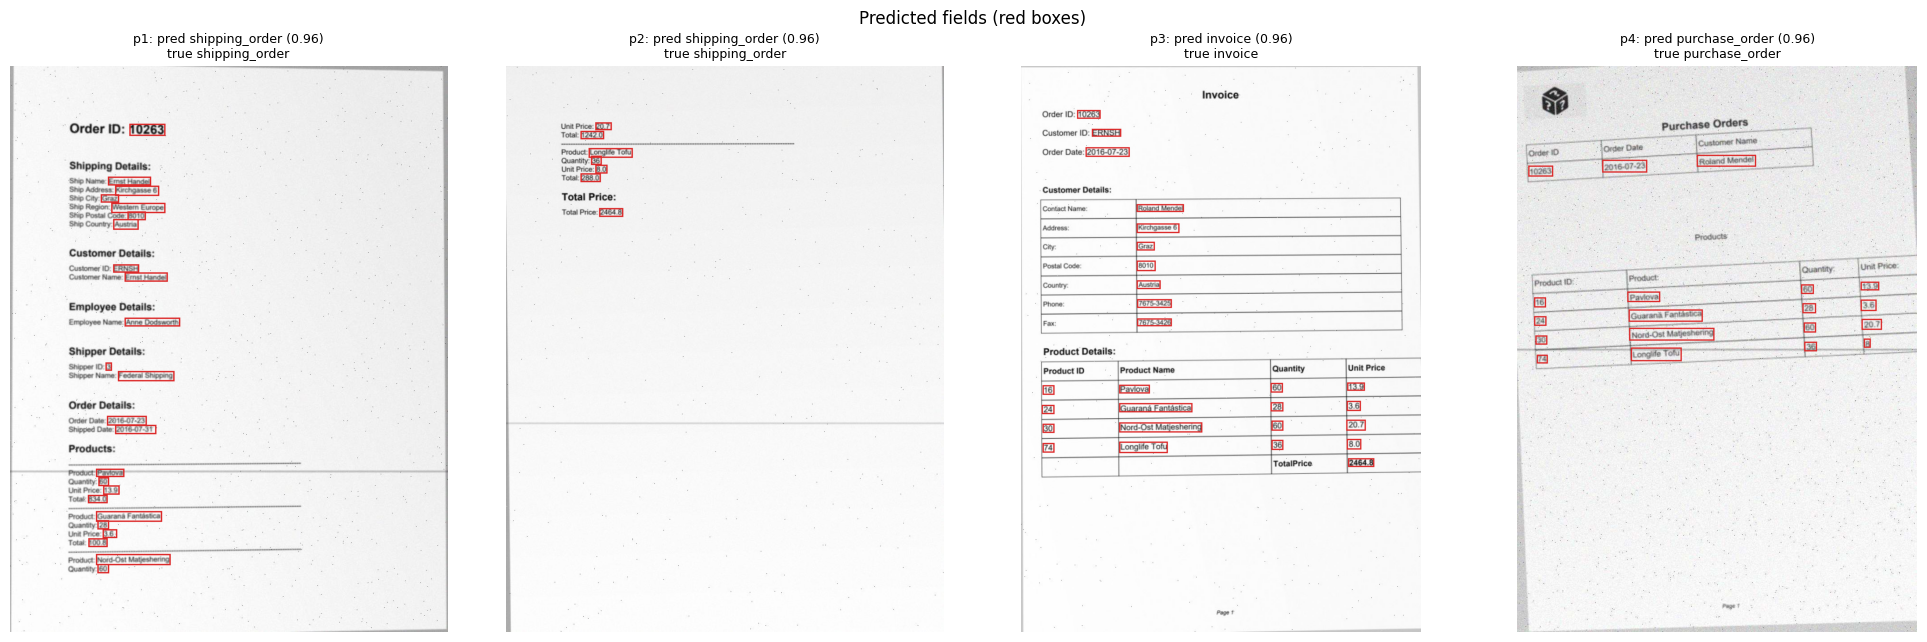

In [14]:
from safetensors import safe_open
out_dir = cfg["output_dir"]
pipe.save(out_dir, fp16=True)                    # all floating-point weights stored as float16
files = []
for f in sorted(Path(out_dir).rglob("*.safetensors")):
    with safe_open(str(f), "pt") as sf:
        keys = list(sf.keys())
        dtypes = sorted({str(sf.get_slice(k).get_dtype()) for k in keys})
    files.append({"file": str(f.relative_to(out_dir)).replace("\\", "/"), "tensors": len(keys),
                  "dtype": ", ".join(dtypes), "MB": f.stat().st_size / 2 ** 20})
display(pd.DataFrame(files).set_index("file").round(2))
size_mb = sum(f.stat().st_size for f in Path(out_dir).rglob("*") if f.is_file()) / 2 ** 20
t0 = time.perf_counter(); served = DocPipeline.load(out_dir, device); print(f"saved {size_mb:.0f} MB -> reloaded in {time.perf_counter() - t0:.1f}s; adapters: {served.backbone.adapters}")

demo = max(splits["test"], key=lambda b: len({p.doc_type for p in b}))
request = [served.page(os.path.join(p.meta["_dir"], p.meta["image"]),                     # image path / bytes / base64
                       open(os.path.join(p.meta["_dir"], p.meta["ocr"]), encoding="utf-8").read(),   # raw TSV text
                       {"doc_id": p.meta["doc_id"], "page_num": p.meta["page_num"]}) for p in demo]
result = served.process(request, cfg["serving"]["review_threshold"])
same = [s["doc_type"] for s in result["segments"]] == [s["doc_type"] for s in pipe.process(demo)["segments"]]
print("true page types:", [p.doc_type for p in demo], "| reloaded fp16 bundle gives the same segments as the in-memory model:", same)
def trim(o):
    if isinstance(o, list) and len(o) > 3: return trim(o[:3]) + [f"... {len(o) - 3} more"]
    if isinstance(o, dict): return {k: trim(v) for k, v in o.items() if k != "bbox"}
    return [trim(x) for x in o] if isinstance(o, list) else o
print(json.dumps(trim(result), indent=1)[:3500])
viz.show_predictions(demo, result)

## 11. Training curves

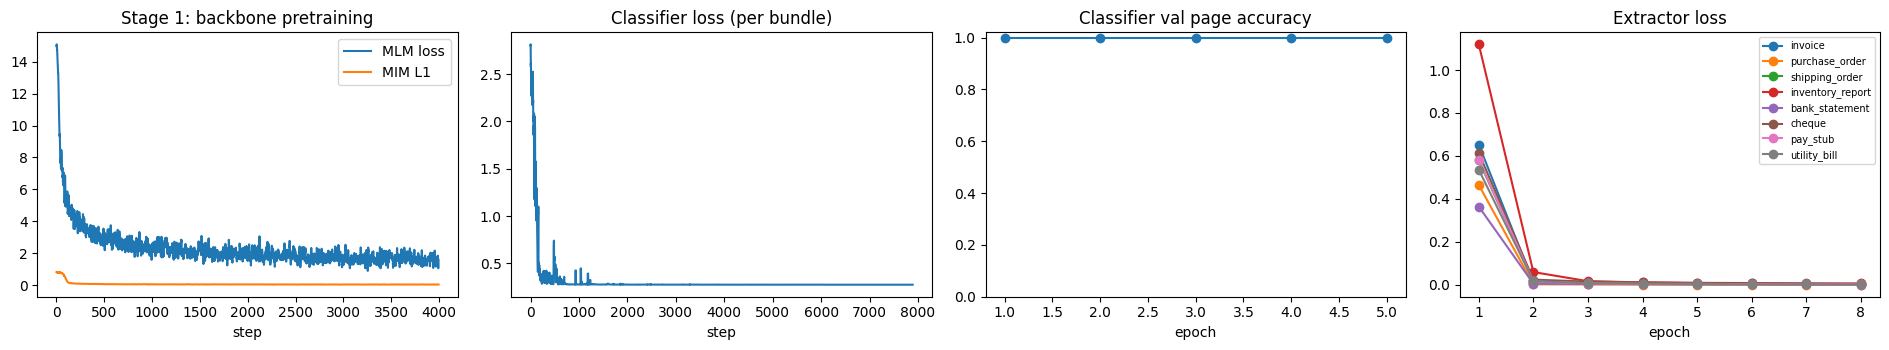

metrics -> artifacts/pipeline\metrics.json


In [15]:
viz.plot_training(pt.history, clf_hist, ie_hist)
summary = {"mode": RUN, "device": str(device), "pretraining_val": {"before": before, "after": after},
           "classification": cls_sum, "extraction": ie_sum.round(4).to_dict(orient="index"),
           "adapter_switch_us": switch_us, "backbone_load_s": load_s, "bundle_MB": size_mb}
with open(os.path.join(out_dir, "metrics.json"), "w") as f:
    json.dump(summary, f, indent=2, default=float)
print("metrics ->", os.path.join(out_dir, "metrics.json"))

## 12. Ablations — what does each part of the backbone recipe buy?
Each variant builds a **fresh** backbone and then repeats exactly the same downstream training
(classifier + 8 extractors, same epochs, seeds, pages and splits). Results are on the same noisy
test split.

| Variant | Backbone |
|---|---|
| `full` | domain pretraining with MLM + MIM (the model trained above) |
| `no_pretrain` | public `layoutlmv3-base` weights; the backbone is never fine-tuned on our documents |
| `mlm_only` | domain pretraining with MLM only (images never masked) |
| `mim_only` | domain pretraining with MIM only (text never masked) |

[no_pretrain] page acc 1.0000 | entity F1 0.9953 | doc value acc 0.9855 | 23.0 min


pretrain step 666/4000  mlm 1.736  mlm_acc 0.651  (88s)


pretrain step 1332/4000  mlm 1.925  mlm_acc 0.592  (178s)


pretrain step 1998/4000  mlm 2.160  mlm_acc 0.505  (270s)


pretrain step 2664/4000  mlm 2.992  mlm_acc 0.483  (357s)


...

pretrain step 3330/4000  mim 0.036  (433s)


pretrain step 3996/4000  mim 0.039  (521s)


[mim_only] page acc 1.0000 | entity F1 0.9939 | doc value acc 0.9840 | 31.7 min


,page_accuracy,macro_f1,boundary_f1,document_exact_match,entity_f1_strict,entity_f1_text,doc_value_accuracy,pretrain_val_mlm,pretrain_val_mlm_acc,pretrain_val_mim,train_minutes
full,1.0,1.0,1.0,1.0,0.9952,0.9952,0.9877,1.2753,0.7516,0.0449,NaN
no_pretrain,1.0,1.0,1.0,1.0,0.9953,0.9953,0.9855,NaN,NaN,NaN,23.0444
mlm_only,1.0,1.0,1.0,1.0,0.9951,0.9951,0.9857,0.9086,0.7914,NaN,31.8522
mim_only,1.0,1.0,1.0,1.0,0.9939,0.9940,0.9840,NaN,NaN,0.0400,31.7205


,full,no_pretrain,mlm_only,mim_only
strict entity F1 by doc type,,,,
invoice,0.9968,0.9977,0.9979,0.9981
purchase_order,0.9991,1.0000,0.9997,1.0000
shipping_order,0.9958,0.9962,0.9952,0.9952
inventory_report,0.9984,0.9984,0.9981,0.9956
bank_statement,0.9991,0.9991,0.9989,0.9986
cheque,0.9878,0.9897,0.9850,0.9860
pay_stub,0.9917,0.9900,0.9917,0.9867
utility_bill,0.9929,0.9915,0.9943,0.9915


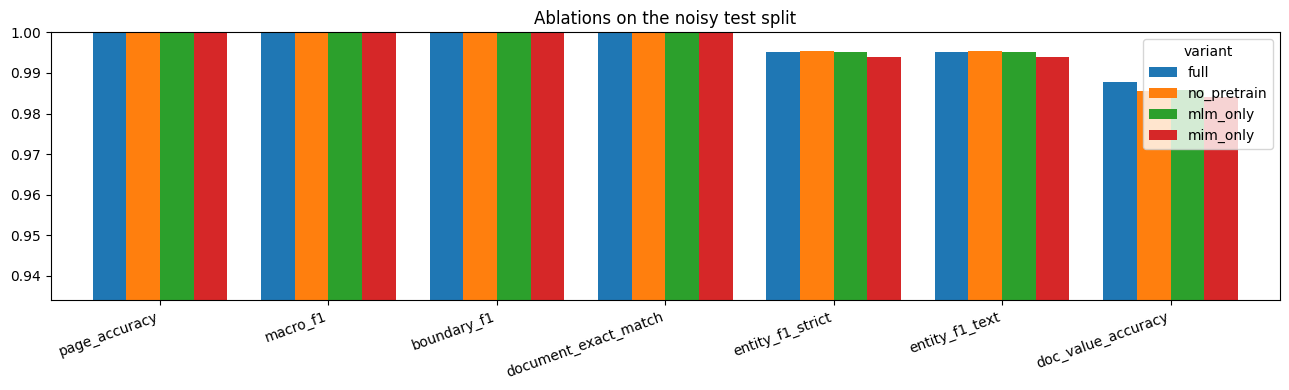

best extraction: no_pretrain (0.9953); no_pretrain vs full: +0.0001 entity F1, +0.0000 page acc; mlm_only vs full: -0.0001 entity F1, +0.0000 page acc; mim_only vs full: -0.0013 entity F1, +0.0000 page acc


In [16]:
from lmv3docs.experiments import VARIANTS, run_variant, summarize
ablation = {"full": summarize(cls_sum, ie_sum, after, None)}
ablation_ie = {"full": ie_sum}
if RUN_ABLATIONS:
    served.backbone.cpu(); pipe.backbone.cpu()                 # free the GPU for the variants
    del served
    torch.cuda.empty_cache() if device.type == "cuda" else None
    for name in ("no_pretrain", "mlm_only", "mim_only"):
        ablation[name], ablation_ie[name] = run_variant(name, cfg, pages, splits, specs, device)
abl = pd.DataFrame(ablation).T
main_cols = ["page_accuracy", "macro_f1", "boundary_f1", "document_exact_match", "entity_f1_strict", "entity_f1_text", "doc_value_accuracy"]
display(abl[main_cols + [c for c in abl.columns if c.startswith("pretrain_val") or c == "train_minutes"]].round(4))
display(pd.DataFrame({k: v["entity_f1_strict"] for k, v in ablation_ie.items()}).round(4)
        .rename_axis("strict entity F1 by doc type"))
ax = abl[main_cols].T.plot.bar(figsize=(13, 4), width=0.8)
lo = max(0.0, float(abl[main_cols].min().min()) - 0.05)
ax.set_ylim(lo, 1.0); ax.set_title("Ablations on the noisy test split"); ax.legend(title="variant")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()
with open(os.path.join(cfg["output_dir"], "ablations.json"), "w") as f:
    json.dump({"variants": abl.to_dict(orient="index"),
               "entity_f1_by_doc_type": {k: v["entity_f1_strict"].to_dict() for k, v in ablation_ie.items()}}, f, indent=2, default=float)
best = abl["entity_f1_strict"].idxmax()
print(f"best extraction: {best} ({abl.loc[best, 'entity_f1_strict']:.4f}); "
      + "; ".join(f"{k} vs full: {abl.loc[k, 'entity_f1_strict'] - abl.loc['full', 'entity_f1_strict']:+.4f} entity F1, "
                  f"{abl.loc[k, 'page_accuracy'] - abl.loc['full', 'page_accuracy']:+.4f} page acc" for k in abl.index if k != "full"))

## 13. End-to-end accuracy against the clean truth — and does training on noise help?
The extraction scores above check that the model **finds** the right words on the noisy page.
This section checks what a business user sees: **is the returned value equal to the true value?**
The true value comes from the clean source page of the same document.

- **`ocr_ceiling`** is the share of true values that OCR on the noisy page still spells correctly.
  No extractor that relies on this OCR can beat it.
- **`of_ceiling`** is the model's value accuracy divided by that ceiling.

Two models are compared on the same noisy test pages:
- the model trained on noisy pages (this run, `artifacts/pipeline/`);
- the model trained earlier on clean pages (`artifacts/pipeline_clean/`).

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd, torch
from lmv3docs import DocPipeline
from lmv3docs.config import load_config
from lmv3docs.datasets import load_rows
from lmv3docs.experiments import end_to_end_values

cfg_e2e = load_config("CONFIG.yml")
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
e2e = {}
for name, path in [("trained on noisy pages", "artifacts/pipeline"), ("trained on clean pages", "artifacts/pipeline_clean")]:
    if not os.path.exists(os.path.join(path, "pipeline.json")):
        print("skipped (not found):", path); continue
    model = DocPipeline.load(path, dev)
    test_pages = [model.fz.page_from_row(r, r["_dir"]) for r in load_rows(cfg_e2e) if r["split"] == "test"]
    e2e[name] = pd.DataFrame(end_to_end_values(model, test_pages)).T
    model.backbone.cpu(); del model
    if dev.type == "cuda": torch.cuda.empty_cache()
first = next(iter(e2e.values()))
table = pd.concat({**{f"value accuracy ({k})": v["value_accuracy"] for k, v in e2e.items()},
                   "OCR ceiling": first["ocr_ceiling"], "true values": first["values"].astype(int)}, axis=1)
display(table.round(4))
for k, v in e2e.items():
    print(f"{k}: {v.loc['ALL', 'value_accuracy']:.4f} of true values exactly right "
          f"= {v.loc['ALL', 'of_ceiling']:.1%} of what this OCR allows (ceiling {v.loc['ALL', 'ocr_ceiling']:.4f})")

C:\Users\Edward Ng\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


D:\Doc Vision\.venv\Lib\site-packages\transformers\modeling_utils.py:1621: FutureWarning: The `device` argument is deprecated and will be removed in v5 of Transformers.
  warnings.warn(


D:\Doc Vision\.venv\Lib\site-packages\transformers\modeling_utils.py:1621: FutureWarning: The `device` argument is deprecated and will be removed in v5 of Transformers.
  warnings.warn(


,value accuracy (trained on noisy pages),value accuracy (trained on clean pages),OCR ceiling,true values
shipping_order,0.8254,0.8178,0.8254,3414
invoice,0.8781,0.8757,0.8781,2872
purchase_order,0.9058,0.9058,0.9058,1784
inventory_report,0.8790,0.8772,0.8796,1678
bank_statement,0.7644,0.7635,0.7644,7978
cheque,0.8315,0.8185,0.8315,540
pay_stub,0.8459,0.8459,0.8459,305
utility_bill,0.8514,0.8514,0.8514,370
ALL,0.8210,0.8184,0.8211,18941


trained on noisy pages: 0.8210 of true values exactly right = 100.0% of what this OCR allows (ceiling 0.8211)
trained on clean pages: 0.8184 of true values exactly right = 99.7% of what this OCR allows (ceiling 0.8211)


## Takeaways
- **Pretraining pays off before any labelling.** MLM and MIM adapt the backbone to your
  documents using only raw pages.
- **One backbone, many adapters.** Each task costs about 2 MB of adapter plus a small head. The
  alternative is a full copy of the model per task.
- **Switching tasks takes microseconds.** Loading another model from disk takes seconds. That
  is what makes a single low-latency endpoint for classification plus many extractors practical.
- **Tasks are isolated.** Retraining or adding a doc type leaves every other model bit-identical.
- **Noise makes the benchmark meaningful.** On clean template renders every metric was 100%. With
  scan noise and re-OCR, the gaps between classes, fields and backbone variants become visible.
- **The ablations quantify the backbone recipe.** Section 12 compares no domain pretraining,
  MLM-only and MIM-only against MLM + MIM under identical downstream training.
- **No leakage, real reading.** Splits are per bundle, and recall on never-seen values shows the
  extractors read pages rather than recalling memorised values.
- **End-to-end, OCR is the bottleneck.** Section 13 shows how close the extracted values come to
  the true values, compared with what the noisy OCR allows.
- Remaining caveat: both sources are still template-based, so evaluate on a labelled sample of
  real documents before relying on these numbers.